In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors


In [2]:
POLLUTANT = "pm10"
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
MAX_CLUSTERS = 8

PROCESSED_DIR = Path("../data/processed")
FEATURES_FILE = PROCESSED_DIR / f"features_{POLLUTANT}.parquet"

In [3]:
df = pd.read_parquet(FEATURES_FILE)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

In [4]:
lag_cols = [f"{POLLUTANT}_lag_{d}" for d in LAGGED_DAYS]
rolling_cols = [f"{POLLUTANT}_rolling_{w}" for w in ROLLING_WINDOWS]
rolling_std_cols = [f"{POLLUTANT}_rolling_std_{w}" for w in ROLLING_WINDOWS]
calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
weather_cols = [
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "wind_speed_10m_mean",
    "precipitation_sum",
    "pressure_msl_mean",
]


In [5]:
base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
required = base_cols + ["date", "station_id", POLLUTANT]
cluster_df = df.dropna(subset=required).copy().reset_index(drop=True)

In [6]:
wind_dummies = pd.get_dummies(cluster_df["wind_category"], prefix="wind")
X_cont = RobustScaler().fit_transform(cluster_df[base_cols])
X = pd.concat([
    pd.DataFrame(X_cont, columns=base_cols),
    wind_dummies.reset_index(drop=True),
], axis=1)

pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X)
print(f"Clustering rows: {len(cluster_df):,} | input features: {X.shape[1]} | PCA components: {X_pca.shape[1]} "
      f"({pca.explained_variance_ratio_.sum():.1%} variance kept)")


Clustering rows: 3,575 | input features: 21 | PCA components: 3 (91.8% variance kept)


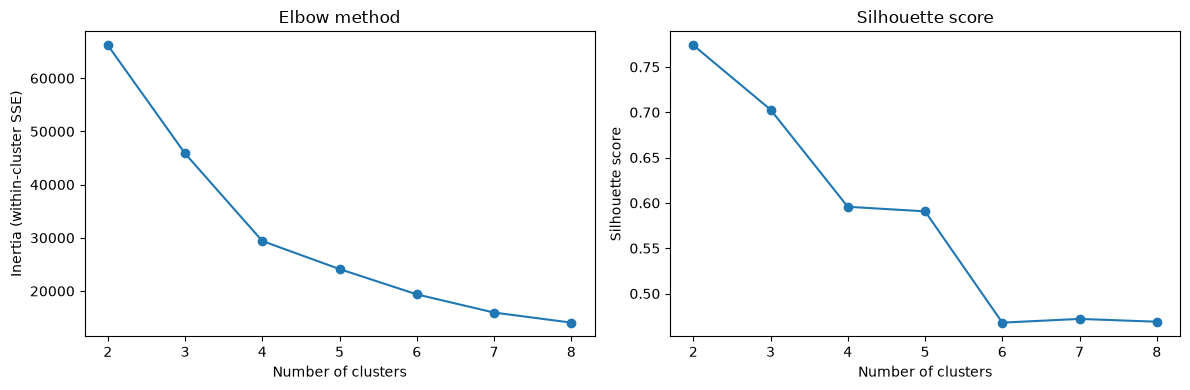

In [7]:
inertias = []
silhouettes = []
ks = range(2, MAX_CLUSTERS + 1)

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow method")

axes[1].plot(list(ks), silhouettes, marker="o")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")

plt.tight_layout()
plt.show()


In [8]:
WINTER_SHARE_THRESHOLD = 0.6

season_map = {12: "winter", 1: "winter", 2: "winter",
              3: "spring", 4: "spring", 5: "spring",
              6: "summer", 7: "summer", 8: "summer",
              9: "autumn", 10: "autumn", 11: "autumn"}

regime_scan = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    labels = km.labels_
    tmp = cluster_df.assign(c=labels)
    pm_by_cluster = tmp.groupby("c")[POLLUTANT].mean()
    top_idx = pm_by_cluster.idxmax()
    top_mask = tmp["c"] == top_idx
    winter_share = tmp.loc[top_mask, "date"].dt.month.map(season_map).eq("winter").mean()
    regime_scan.append({
        "k": k,
        "silhouette": silhouette_score(X_pca, labels),
        "top_cluster_size": int(top_mask.sum()),
        "top_pm_mean": round(float(pm_by_cluster.loc[top_idx]), 1),
        "top_winter_share": round(float(winter_share), 2),
    })

scan_df = pd.DataFrame(regime_scan)
display(scan_df)

silhouette_best_k = int(ks[np.argmax(silhouettes)])
winter_candidates = scan_df.loc[scan_df["top_winter_share"] >= WINTER_SHARE_THRESHOLD]
N_CLUSTERS = int(winter_candidates["k"].min()) if len(winter_candidates) else silhouette_best_k
best_k = N_CLUSTERS

print(f"Silhouette-best k: {silhouette_best_k}")
print(f"Chosen k: {N_CLUSTERS} (smallest k whose highest-pollution cluster is winter-dominant; "
      f"silhouette alone favours {silhouette_best_k}, a dense season-neutral catch-all cluster)")

,k,silhouette,top_cluster_size,top_pm_mean,top_winter_share
0,2,0.773953,3275,48.6,0.26
1,3,0.702864,3177,49.1,0.26
2,4,0.595731,418,105.2,0.81
3,5,0.590682,413,105.5,0.81
4,6,0.467945,193,127.9,0.93
5,7,0.472044,193,127.9,0.93
6,8,0.468951,193,127.9,0.93


Silhouette-best k: 2
Chosen k: 4 (smallest k whose highest-pollution cluster is winter-dominant; silhouette alone favours 2, a dense season-neutral catch-all cluster)


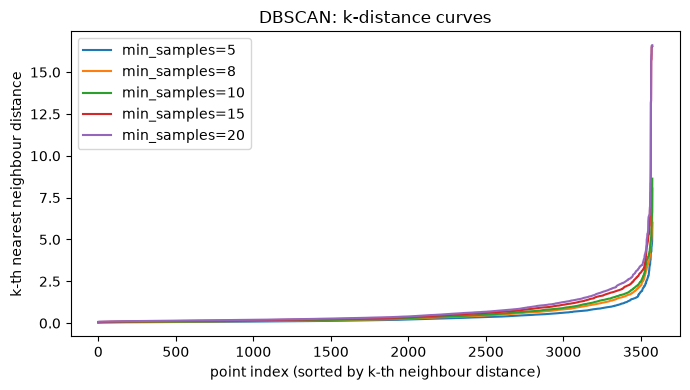

DBSCAN grid search: eps=1.40, min_samples=10 -> 4 clusters, 5.4% noise, silhouette=0.777


In [9]:
DBSCAN_MIN_SAMPLES_CANDIDATES = [5, 8, 10, 15, 20]

fig, ax = plt.subplots(figsize=(7, 4))
for ms in DBSCAN_MIN_SAMPLES_CANDIDATES:
    nn = NearestNeighbors(n_neighbors=ms).fit(X_pca)
    dist, _ = nn.kneighbors(X_pca)
    ax.plot(np.sort(dist[:, -1]), label=f"min_samples={ms}")
ax.set_xlabel("point index (sorted by k-th neighbour distance)")
ax.set_ylabel("k-th nearest neighbour distance")
ax.set_title("DBSCAN: k-distance curves")
ax.legend()
plt.tight_layout()
plt.show()

grid_results = []
for ms in DBSCAN_MIN_SAMPLES_CANDIDATES:
    for eps in np.arange(0.3, 1.51, 0.05):
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_pca)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_frac = (labels == -1).mean()
        if noise_frac > 0.15 or not (2 <= n_clusters <= 6):
            continue
        sil = silhouette_score(X_pca[labels != -1], labels[labels != -1])
        score = sil - 0.30 * noise_frac
        grid_results.append({"eps": eps, "min_samples": ms, "silhouette": sil,
                             "n_clusters": n_clusters, "noise_frac": noise_frac,
                             "score": score})

best_dbscan = max(grid_results, key=lambda r: r["score"])
DBSCAN_EPS = best_dbscan["eps"]
DBSCAN_MIN_SAMPLES = best_dbscan["min_samples"]
print(f"DBSCAN grid search: eps={DBSCAN_EPS:.2f}, min_samples={DBSCAN_MIN_SAMPLES} "
      f"-> {best_dbscan['n_clusters']} clusters, {best_dbscan['noise_frac']:.1%} noise, "
      f"silhouette={best_dbscan['silhouette']:.3f}")


In [10]:
N_CLUSTERS = best_k

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

gmm = GaussianMixture(n_components=N_CLUSTERS, random_state=42)
gmm_labels = gmm.fit_predict(X_pca)

dbscan = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES)
dbscan_labels = dbscan.fit_predict(X_pca)

sil_kmeans = silhouette_score(X_pca, kmeans_labels)
sil_gmm = silhouette_score(X_pca, gmm_labels)
sil_dbscan = silhouette_score(X_pca[dbscan_labels != -1], dbscan_labels[dbscan_labels != -1])
print(f"Silhouette K-Means: {sil_kmeans:.3f}")
print(f"Silhouette GMM    : {sil_gmm:.3f}")
print(f"Silhouette DBSCAN : {sil_dbscan:.3f}")

cluster_df["cluster_kmeans"] = kmeans_labels
cluster_df["cluster_gmm"] = gmm_labels
cluster_df["cluster_dbscan"] = dbscan_labels


Silhouette K-Means: 0.596
Silhouette GMM    : 0.246
Silhouette DBSCAN : 0.777


In [11]:
SEASONS = ["winter", "spring", "summer", "autumn"]

def describe_clusters(frame, label_col):
    frame = frame.copy()
    frame[label_col] = frame[label_col].map(lambda v: "-1 (noise)" if v == -1 else str(v))
    frame["month"] = frame["date"].dt.month
    frame["season"] = frame["month"].map({
        12: "winter", 1: "winter", 2: "winter",
        3: "spring", 4: "spring", 5: "spring",
        6: "summer", 7: "summer", 8: "summer",
        9: "autumn", 10: "autumn", 11: "autumn",
    })

    summary = (
        frame.groupby(label_col)
        .agg(count=("station_id", "size"),
             pm_mean=("pm25" if POLLUTANT == "pm25" else "pm10", "mean"),
             mean_month=("month", "mean"),
             n_stations=("station_id", "nunique"))
        .reset_index()
    )

    season_counts = frame.groupby([label_col, "season"]).size().reset_index(name="n")
    season_counts["share"] = season_counts["n"] / season_counts.groupby(label_col)["n"].transform("sum")
    season_shares = (
        season_counts.pivot(index=label_col, columns="season", values="share")
        .reindex(columns=SEASONS)
        .fillna(0.0)
        .add_prefix("share_")
        .reset_index()
    )

    summary = summary.merge(season_shares, on=label_col, how="left")
    summary["mean_month"] = summary["mean_month"].round(1)
    summary["top_season"] = summary[[f"share_{s}" for s in SEASONS]].idxmax(axis=1).str.replace("share_", "")
    return summary

In [12]:
for label_col in ["cluster_kmeans", "cluster_gmm", "cluster_dbscan"]:
    print(label_col)
    display(describe_clusters(cluster_df, label_col))

cluster_kmeans


,cluster_kmeans,count,pm_mean,mean_month,n_stations,share_winter,share_spring,share_summer,share_autumn,top_season
0,0,2757,40.664922,7.0,5,0.176279,0.247733,0.289082,0.286906,summer
1,1,94,19.369871,7.8,5,0.085106,0.329787,0.063830,0.521277,autumn
2,2,306,33.033542,7.3,5,0.245098,0.238562,0.133987,0.382353,autumn
3,3,418,105.170771,6.0,5,0.808612,0.011962,0.000000,0.179426,winter


cluster_gmm


,cluster_gmm,count,pm_mean,mean_month,n_stations,share_winter,share_spring,share_summer,share_autumn,top_season
0,0,2036,43.952737,7.0,5,0.197446,0.223477,0.299116,0.279961,summer
1,1,255,24.158396,7.5,5,0.086275,0.356863,0.145098,0.411765,autumn
2,2,390,38.020537,7.2,5,0.294872,0.233333,0.102564,0.369231,autumn
3,3,894,64.348358,6.4,5,0.411633,0.173378,0.176734,0.238255,winter


cluster_dbscan


,cluster_dbscan,count,pm_mean,mean_month,n_stations,share_winter,share_spring,share_summer,share_autumn,top_season
0,-1 (noise),192,70.220038,6.1,5,0.666667,0.114583,0.031250,0.187500,winter
1,0,3343,46.022951,6.9,5,0.233024,0.227341,0.250673,0.288962,autumn
2,1,14,14.265185,10.1,5,0.000000,0.000000,0.000000,1.000000,autumn
3,2,11,13.099022,7.4,5,0.000000,0.454545,0.000000,0.545455,autumn
4,3,15,21.522119,7.9,5,0.000000,0.333333,0.000000,0.666667,autumn


In [13]:
LABELS_OUT = PROCESSED_DIR / f"clustering_labels_{POLLUTANT}.parquet"
SUMMARY_COLS = ["station_id", "station_name", "date", POLLUTANT, "cluster_kmeans", "cluster_gmm", "cluster_dbscan"]

In [14]:
cluster_df[SUMMARY_COLS].to_parquet(LABELS_OUT, index=False)

summary_list = []
for label_col in ["cluster_kmeans", "cluster_gmm", "cluster_dbscan"]:
    s = describe_clusters(cluster_df, label_col)
    s["method"] = label_col
    summary_list.append(s)
summary_df = pd.concat(summary_list, ignore_index=True)
summary_df.to_parquet(PROCESSED_DIR / f"clustering_summary_{POLLUTANT}.parquet", index=False)

print(f"Saved: clustering_labels_{POLLUTANT}.parquet")
print(f"Saved: clustering_summary_{POLLUTANT}.parquet")


Saved: clustering_labels_pm10.parquet
Saved: clustering_summary_pm10.parquet
